In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')
print(df.shape)
df.head()

(2443651, 9)


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [4]:
df[['category', 'price', 'stars']].isna().sum()

category    0
price       0
stars       0
dtype: int64

# parte1 : Comprension de las categorias de productos

1.TABLAS DE FRECUENCIA:

In [5]:
frec_cat = df['category'].value_counts()
porcentaje = df['category'].value_counts(normalize=True)
tabla_cat = pd.DataFrame({'frecuencia': frec_cat, 'porcentaje (%)': porcentaje})
tabla_cat.head(10)

,frecuencia,porcentaje (%)
category,,
Sports & Outdoors,836265,0.342219
Beauty,19312,0.007903
"Handmade Clothing, Shoes & Accessories",19229,0.007869
Bath & Body,19092,0.007813
Birthday Gifts,18978,0.007766
Manicure & Pedicure Products,18940,0.007751
Skin Care,18769,0.007681
Make-up,18756,0.007675
Hair Care,18735,0.007667


In [6]:
top5_cat = tabla_cat.head(5)
top5_cat

,frecuencia,porcentaje (%)
category,,
Sports & Outdoors,836265,0.342219
Beauty,19312,0.007903
"Handmade Clothing, Shoes & Accessories",19229,0.007869
Bath & Body,19092,0.007813
Birthday Gifts,18978,0.007766


2.VISUALIZACIONES

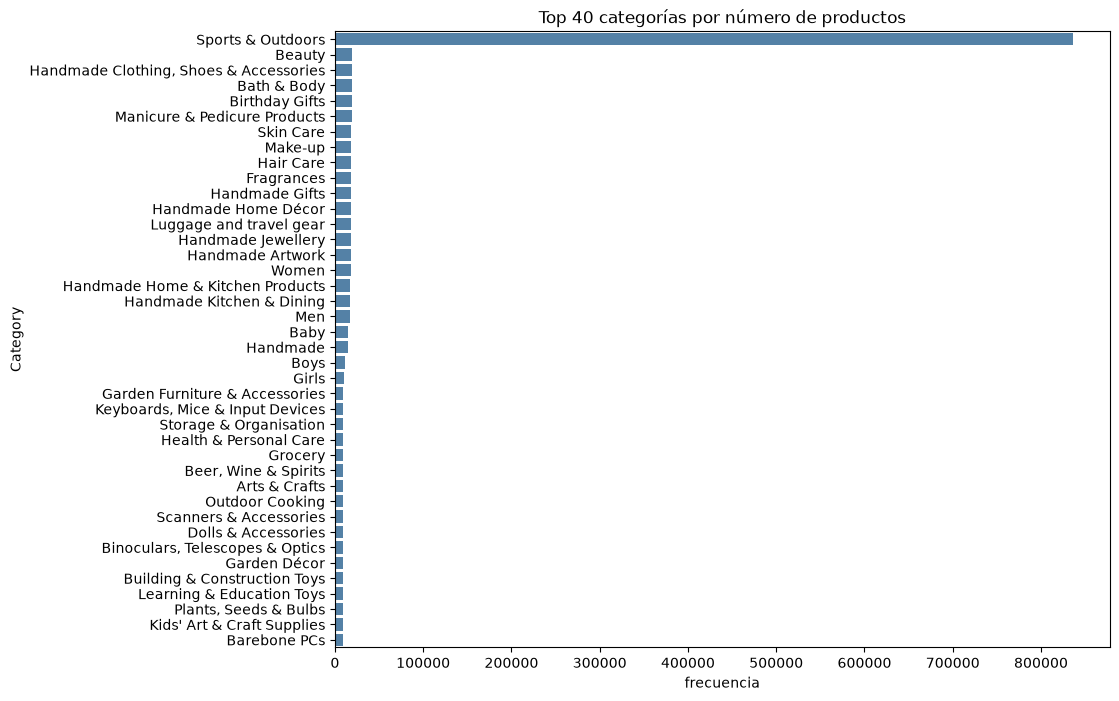

In [7]:
top40 = frec_cat.head(40)

plt.figure(figsize=(10, 8))
sns.barplot(x=top40.values, y=top40.index, color='steelblue')
plt.title('Top 40 categorías por número de productos')
plt.xlabel('frecuencia')
plt.ylabel('Category')
plt.show()

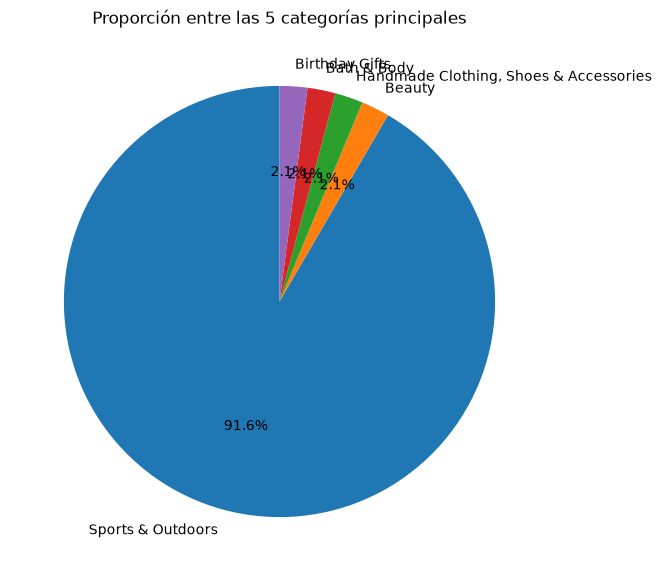

In [8]:
top5 = frec_cat.head(5)
plt.figure(figsize=(7, 7))
plt.pie(top5.values, labels=top5.index, autopct='%1.1f%%', startangle=90)
plt.title('Proporción entre las 5 categorías principales')
plt.show()

In [ ]:
# la categoria que prodomina y por mucho en la lista es : 'Sports & Outdoors'

# parte2: Profundizando en la fijacion de precios de los productos

1.Medidas de centralidad

In [31]:
precio = df['price']
media_p = precio.mean()
mediana_p = precio.median()
moda_p = precio.mode()[0]

print(f'media: {media_p}')
print(f'mediana: {mediana_p}')
print(f'moda: {moda_p}')

media: 89.24380943923661
mediana: 19.09
moda: 9.99


2.Medidas de dispersión

In [10]:
q1_p = precio.quantile(0.25)
q3_p = precio.quantile(0.75)
print(f'Varianza:            {precio.var()}')
print(f'Desviación estándar: {precio.std()}')
print(f'Mínimo:              {precio.min()}')
print(f'Máximo:              {precio.max()}')
print(f'Rango:               {precio.max() - precio.min()}')
print(f'Rango Intercuartil:  {q3_p - q1_p}')

Varianza:            119445.48532254901
Desviación estándar: 345.60886175349873
Mínimo:              0.0
Máximo:              100000.0
Rango:               100000.0
Rango Intercuartil:  36.0


3.Visualizaciones

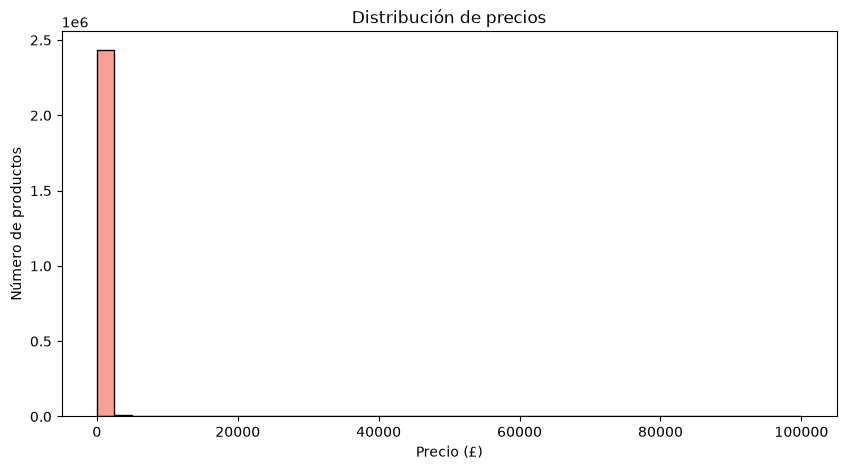

In [24]:
plt.figure(figsize=(10, 5))
sns.histplot(precio, bins=40, color ='salmon')
plt.title('Distribución de precios')
plt.xlabel('Precio (£)')
plt.ylabel('Número de productos')
plt.show()

In [ ]:
#es dificil de leer porque unos productos muy caros estiral el eje X, y casi todos los datos quedan aprentados en la primera barra
#Solucionaria, limitar el grafico usando un rango que quite esos productos.

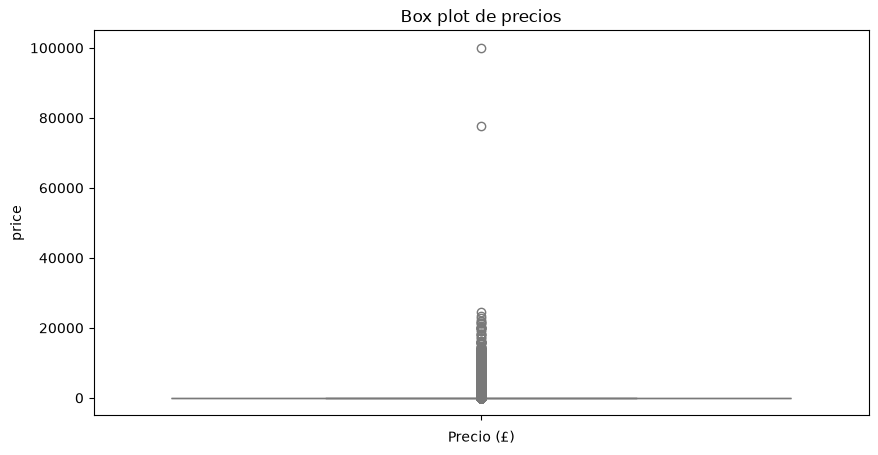

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(data = df['price'], color = 'lightblue')
plt.title('Box plot de precios')
plt.show()

# parte3 : Valoraciones

In [29]:
rating = df['stars'].value_counts
rating

<bound method IndexOpsMixin.value_counts of 0          4.7
1          4.7
2          4.7
3          4.7
4          4.6
          ... 
2443646    0.0
2443647    0.0
2443648    0.0
2443649    4.3
2443650    4.5
Name: stars, Length: 2443651, dtype: float64>

1.Medidas de centralidad

In [32]:
rating = df['stars']
media_r = rating.mean()
mediana_r = rating.median()
moda_r = rating.mode()[0]

print(f'media: {media_r}')
print(f'mediana: {mediana_r}')
print(f'moda: {moda_r}')

media: 2.152836472966066
mediana: 0.0
moda: 0.0


In [ ]:
#segun los datos hay una tendencia al rating = 0 , pero tengo sospecha que es una 'NO' valoracion y no mala puntuación

2.Medidas de dispercion

In [33]:
q1_r = rating.quantile(0.25)
q3_r = rating.quantile(0.75)
print(f'Varianza:            {rating.var()}')
print(f'Desviación estándar: {rating.std()}')
print(f'Mínimo:              {rating.min()}')
print(f'Máximo:              {rating.max()}')
print(f'Rango:               {rating.max() - rating.min()}')
print(f'Rango Intercuartil:  {q3_r - q1_r}')

Varianza:            4.817434029796864
Desviación estándar: 2.194865378513421
Mínimo:              0.0
Máximo:              5.0
Rango:               5.0
Rango Intercuartil:  4.4


In [ ]:
#segun los datos existe una gran variacion, pero es la variacion que proviene de todos los productos sin valoraciones

3.Forma de la distribucion

In [35]:
print(rating.skew())
print(rating.kurt())

0.08120735761080881
-1.9260061280432994


In [ ]:
# la asimetria van hascia los balores bajos
#curtosis: no hay pico central , sino dos montones de datos extremos

4.Visualizaciones

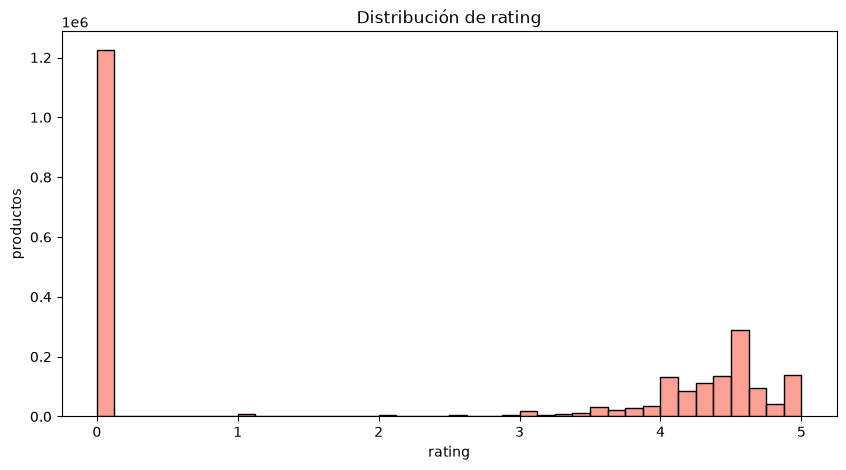

In [41]:
plt.figure(figsize=(10, 5))
sns.histplot(rating, bins=40, color ='salmon')
plt.title('Distribución de rating')
plt.xlabel('rating')
plt.ylabel('productos')
plt.show()

In [ ]:
#la calificacion mas comun es 0